In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import pandas as pd

df = pd.read_csv('/content/drive/MyDrive/MesinLearning/Praktikum06/Data/StudentsAcademicPerformance.csv')

df.head()

,gender,NationalITy,PlaceofBirth,StageID,GradeID,SectionID,Topic,Semester,Relation,raisedhands,VisITedResources,AnnouncementsView,Discussion,ParentAnsweringSurvey,ParentschoolSatisfaction,StudentAbsenceDays,Class
0,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,15,16,2,20,Yes,Good,Under-7,M
1,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,20,20,3,25,Yes,Good,Under-7,M
2,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,10,7,0,30,No,Bad,Above-7,L
3,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,30,25,5,35,No,Bad,Above-7,L
4,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,40,50,12,50,No,Bad,Above-7,M


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 480 entries, 0 to 479
Data columns (total 17 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   gender                    480 non-null    object
 1   NationalITy               480 non-null    object
 2   PlaceofBirth              480 non-null    object
 3   StageID                   480 non-null    object
 4   GradeID                   480 non-null    object
 5   SectionID                 480 non-null    object
 6   Topic                     480 non-null    object
 7   Semester                  480 non-null    object
 8   Relation                  480 non-null    object
 9   raisedhands               480 non-null    int64 
 10  VisITedResources          480 non-null    int64 
 11  AnnouncementsView         480 non-null    int64 
 12  Discussion                480 non-null    int64 
 13  ParentAnsweringSurvey     480 non-null    object
 14  ParentschoolSatisfaction  

In [7]:
df.describe()

,raisedhands,VisITedResources,AnnouncementsView,Discussion
count,480.000000,480.000000,480.000000,480.000000
mean,46.775000,54.797917,37.918750,43.283333
std,30.779223,33.080007,26.611244,27.637735
min,0.000000,0.000000,0.000000,1.000000
25%,15.750000,20.000000,14.000000,20.000000
50%,50.000000,65.000000,33.000000,39.000000
75%,75.000000,84.000000,58.000000,70.000000
max,100.000000,99.000000,98.000000,99.000000


In [8]:
df["Class"].unique()

array(['M', 'L', 'H'], dtype=object)

In [9]:
df["Class"].value_counts()

,count
Class,
M,211
H,142
L,127


In [10]:
X = df.drop(columns=['Class'])

y = df['Class']

In [11]:
X.head()

,gender,NationalITy,PlaceofBirth,StageID,GradeID,SectionID,Topic,Semester,Relation,raisedhands,VisITedResources,AnnouncementsView,Discussion,ParentAnsweringSurvey,ParentschoolSatisfaction,StudentAbsenceDays
0,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,15,16,2,20,Yes,Good,Under-7
1,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,20,20,3,25,Yes,Good,Under-7
2,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,10,7,0,30,No,Bad,Above-7
3,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,30,25,5,35,No,Bad,Above-7
4,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,40,50,12,50,No,Bad,Above-7


In [12]:
y.head()

,Class
0,M
1,M
2,L
3,L
4,M


In [13]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Memisahkan fitur numerik dan kategorikal
numerical_features = X.select_dtypes(include=['int64', 'float64']).columns
categorical_features = X.select_dtypes(include=['object', 'category']).columns

# Preprocessing data
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

# Membuat pipeline preprocessing dan model SVM
model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', SVC(kernel='linear'))
])

# Membagi dataset menjadi data latih dan data uji
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Melatih model SVM
model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  Index(['raisedhands', 'VisITedResources', 'AnnouncementsView', 'Discussion'], dtype='object')),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  Index(['gender', 'NationalITy', 'PlaceofBirth', 'StageID', 'GradeID',
       'SectionID', 'Topic', 'Semester', 'Relation', 'ParentAnsweringSurvey',
       'ParentschoolSatisfaction', 'StudentAbsenceDays'],
      dtype='object'))])),
                ('classifier', SVC(kernel='linear'))])

In [14]:
y_pred = model.predict(X_test)

print(f"Akurasi: {accuracy_score(y_test, y_pred) * 100:.2f}%")

print("\nLaporan Klasifikasi:\n")
print(classification_report(y_test, y_pred, zero_division=0))

Akurasi: 76.04%

Laporan Klasifikasi:

              precision    recall  f1-score   support

           H       0.83      0.69      0.75        29
           L       0.80      0.80      0.80        25
           M       0.70      0.79      0.74        42

    accuracy                           0.76        96
   macro avg       0.78      0.76      0.77        96
weighted avg       0.77      0.76      0.76        96




Confusion Matrix:

[[20  0  9]
 [ 0 20  5]
 [ 4  5 33]]


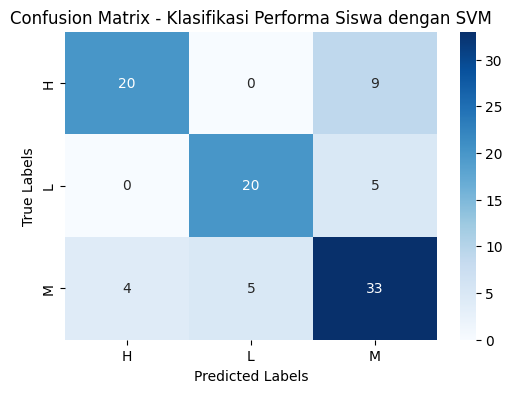

In [15]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import seaborn as sns

print("\nConfusion Matrix:\n")
print(confusion_matrix(y_test, y_pred, labels=model.classes_))

cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.title("Confusion Matrix - Klasifikasi Performa Siswa dengan SVM")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.show()

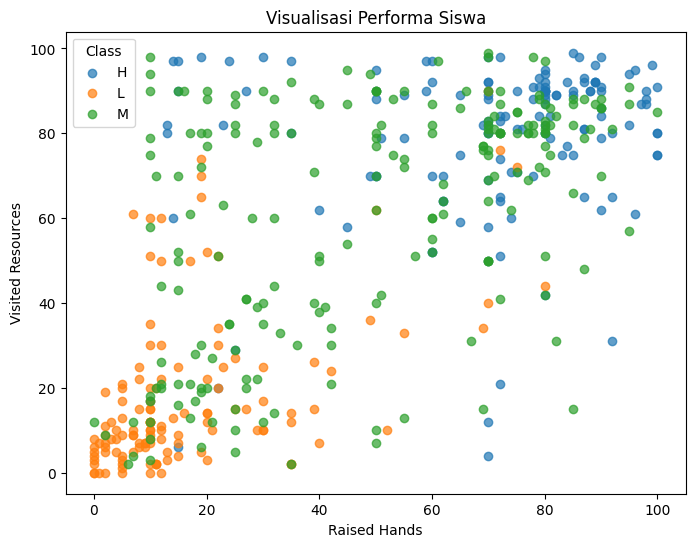

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

for class_label in sorted(df['Class'].unique()):
    subset = df[df['Class'] == class_label]

    plt.scatter(
        subset['raisedhands'],
        subset['VisITedResources'],
        label=class_label,
        alpha=0.7
    )

plt.xlabel('Raised Hands')
plt.ylabel('Visited Resources')
plt.title('Visualisasi Performa Siswa')
plt.legend(title='Class')
plt.show()

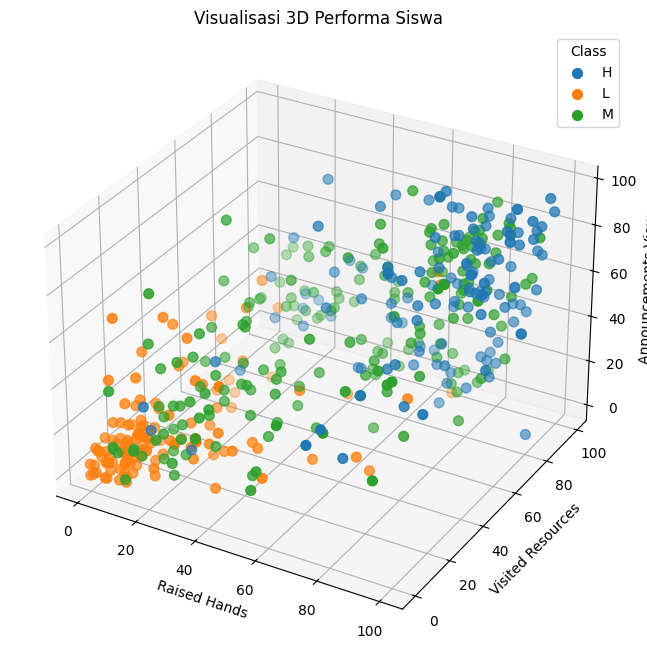

In [17]:
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt

from mpl_toolkits.mplot3d import Axes3D

# Encode label kelas menjadi angka
le = LabelEncoder()

df['ClassEncoded'] = le.fit_transform(df['Class'])

# Membuat plot 3D
fig = plt.figure(figsize=(10, 8))

ax = fig.add_subplot(111, projection='3d')

# Mengambil label kelas
labels = le.classes_

# Visualisasi setiap kelas
for i, class_label in enumerate(labels):
    subset = df[df['Class'] == class_label]

    ax.scatter(
        subset['raisedhands'],
        subset['VisITedResources'],
        subset['AnnouncementsView'],
        label=class_label,
        s=50
    )

ax.set_xlabel('Raised Hands')
ax.set_ylabel('Visited Resources')
ax.set_zlabel('Announcements View')

ax.set_title('Visualisasi 3D Performa Siswa')

ax.legend(title='Class')

plt.show()